# Тематическое моделирование

In [8]:
!pip install pymorphy3 gensim pyLDAvis wordcloud -q
import pandas as pd
import numpy as np
import re
import string
import nltk
import pymorphy3
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation, NMF, TruncatedSVD
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis
import warnings
warnings.filterwarnings('ignore')

nltk.download('stopwords', quiet=False)
nltk.download('punkt', quiet=False)
nltk.download('punkt_tab', quiet=False)

from wordcloud import WordCloud
import matplotlib.pyplot as plt

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/salomon/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /Users/salomon/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/salomon/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [10]:
df = pd.read_csv('merged_movies.csv')
print(f"Загружено фильмов: {len(df)}")
df.head()

Загружено фильмов: 340


,title,year,country,rating,rating_imdb,description,genre,votes,source
0,1+1,2011,Франция,9.0,0.0,Реальная история дружбы «принца» и «нищего». П...,"Драма, Комедия, Биография",0,top250_only
1,11:14,2003,США,7.2,0.0,Загадочный триллер о судьбе и играх времени. Н...,"Триллер, Драма, Детектив, Ужасы, Криминал",0,top250_only
2,18-летняя,2026,Корея Южная,0.0,0.0,Старшеклассница Сун-джон мечтает поскорее окон...,драма,1,api_only
3,1941. Крылья над Берлином,2022,Россия,8.8,0.0,Август 1941-го года. Советская авиация готовит...,"Драма, Боевик, История, Военный",0,top250_only
4,30 секунд,2024,Россия,8.5,0.0,"В обычной жизни Артем работает программистом, ...","Драма, Комедия",0,top250_only


# 1. ПРЕДОБРАБОТКА ТЕКСТА (как в вашем ноутбуке)


In [11]:
# Удаляем спецсимволы
st = '\xa0—'
def remove_othersymbol(text):
    if isinstance(text, str):
        return ''.join([ch if ch not in st else ' ' for ch in text])
    return text

df['prep_text'] = df['description'].fillna('').astype(str).apply(lambda x: remove_othersymbol(x.lower()))

# Удаляем пунктуацию
def remove_punctuation(text):
    return ''.join([ch for ch in text if ch not in string.punctuation])

df['prep_text'] = df['prep_text'].apply(remove_punctuation)

# Загрузка стоп-слов и лемматизация
russian_stopwords = stopwords.words("russian")
russian_stopwords.extend(['т.д.', 'т', 'д', 'это', 'который', 'свой', 'своём', 'всем', 'всё', 'её', 'оба', 'ещё', 
                         'должный', 'фильм', 'кино', 'смотреть', 'год', 'снят', 'рассказывает', 'история', 
                         'оказывается', 'вдруг', 'наконец', 'также', 'который', 'этот', 'эта', 'это', 'эти'])

nltk.download('punkt_tab', quiet=True)
morph = pymorphy3.MorphAnalyzer(lang='ru')

def lemmatize_text(text):
    try:
        tokens = word_tokenize(text)
        lemmas = []
        for word in tokens:
            if word not in russian_stopwords and len(word) > 2:
                p = morph.parse(word)[0]
                lemmas.append(p.normal_form)
        return " ".join(lemmas)
    except Exception as e:
        return text

df['text_lemm'] = df['prep_text'].apply(lemmatize_text)

print(f"Пример лемматизированного текста:\n{df['text_lemm'].iloc[0][:300]}...")

Пример лемматизированного текста:
реальный дружба принц нищий парализовать богатый аристократ филипп искать помощник способный стать рука нога собеседование приходить иммигрантсенегалец дрисс который один цель получить очередной отказ продлить пособие безработица неожиданно толпа квалифицировать обученный специалист филипп выбирать ...


# 2. ВЕКТОРИЗАЦИЯ

In [12]:
# CountVectorizer для LDA (лучше работает с частотами)
count_vec = CountVectorizer(max_df=0.7, min_df=2, max_features=5000, ngram_range=(1, 2))
count_matrix = count_vec.fit_transform(df['text_lemm'])
feature_names = count_vec.get_feature_names_out()
print(f"Размер матрицы частот: {count_matrix.shape}")

# TF-IDF для NMF и LSA
tfidf_vectorizer = TfidfVectorizer(max_df=0.7, min_df=2, max_features=5000, ngram_range=(1, 2))
tfidf_matrix = tfidf_vectorizer.fit_transform(df['text_lemm'])
print(f"Размер TF-IDF матрицы: {tfidf_matrix.shape}")

Размер матрицы частот: (340, 2277)
Размер TF-IDF матрицы: (340, 2277)


# 3. ТЕМАТИЧЕСКОЕ МОДЕЛИРОВАНИЕ

In [13]:
n_topics = 7  

# Подготовка корпуса для Gensim
from gensim.corpora import Dictionary
from gensim.models import LdaMulticore, CoherenceModel

# Токенизируем текст для Gensim
df['tokens'] = df['text_lemm'].apply(lambda x: x.split())

gensim_dictionary = Dictionary(df['tokens'])
gensim_dictionary.filter_extremes(no_below=5, no_above=0.5)  # Фильтруем редкие и частые слова
gensim_corpus = [gensim_dictionary.doc2bow(text) for text in df['tokens']]

lda_gensim = LdaMulticore(corpus=gensim_corpus, num_topics=n_topics, id2word=gensim_dictionary,
                          passes=10, random_state=42, workers=4)

# Выводим темы
for idx, topic in lda_gensim.print_topics(num_words=10):
    print(f"Тема {idx+1}: {topic}")

# Когерентность модели
coherence_model = CoherenceModel(model=lda_gensim, texts=df['tokens'], 
                                 dictionary=gensim_dictionary, coherence='c_v')
coherence_value = coherence_model.get_coherence()
print(f"\nКогерентность модели LDA: {coherence_value:.4f}")

# Визуализация LDA (интерактивная)
pyLDAvis.enable_notebook()
vis_data = gensimvis.prepare(lda_gensim, gensim_corpus, gensim_dictionary)
vis_data  # Отобразит интерактивный график

# ----- LDA (Sklearn) -----
lda_sklearn = LatentDirichletAllocation(n_components=n_topics, random_state=42,
                                        learning_method='online', max_iter=100)
lda_sklearn.fit(count_matrix)

for topic_idx, topic in enumerate(lda_sklearn.components_):
    top_words_idx = topic.argsort()[:-11:-1]
    top_words = [feature_names[i] for i in top_words_idx]
    print(f"Тема {topic_idx+1}: {', '.join(top_words)}")

# ----- NMF -----
nmf_model = NMF(n_components=n_topics, random_state=42, init='nndsvd')
nmf_model.fit(tfidf_matrix)

for topic_idx, topic in enumerate(nmf_model.components_):
    top_words_idx = topic.argsort()[:-11:-1]
    top_words = [tfidf_vectorizer.get_feature_names_out()[i] for i in top_words_idx]
    print(f"Тема {topic_idx+1}: {', '.join(top_words)}")

# ----- LSA (TruncatedSVD) -----
lsa_model = TruncatedSVD(n_components=n_topics, random_state=42)
lsa_model.fit(tfidf_matrix)

for topic_idx, topic in enumerate(lsa_model.components_):
    top_words_idx = topic.argsort()[:-11:-1]
    top_words = [tfidf_vectorizer.get_feature_names_out()[i] for i in top_words_idx]
    print(f"Тема {topic_idx+1}: {', '.join(top_words)}")

Тема 1: 0.029*"свой" + 0.022*"жизнь" + 0.016*"девушка" + 0.015*"который" + 0.014*"год" + 0.013*"стать" + 0.011*"талант" + 0.011*"один" + 0.008*"дело" + 0.008*"пытаться"
Тема 2: 0.017*"жизнь" + 0.016*"который" + 0.014*"свой" + 0.013*"друг" + 0.012*"время" + 0.011*"стать" + 0.011*"год" + 0.010*"саша" + 0.010*"парень" + 0.009*"становиться"
Тема 3: 0.025*"который" + 0.014*"жизнь" + 0.014*"вместе" + 0.013*"решить" + 0.012*"свой" + 0.011*"бизнес" + 0.011*"ребёнок" + 0.010*"женщина" + 0.009*"проблема" + 0.009*"начинать"
Тема 4: 0.023*"который" + 0.022*"свой" + 0.015*"день" + 0.012*"любовь" + 0.011*"семья" + 0.010*"человек" + 0.009*"жизнь" + 0.009*"однако" + 0.009*"друг" + 0.008*"вместе"
Тема 5: 0.016*"который" + 0.014*"работа" + 0.014*"дело" + 0.013*"жизнь" + 0.011*"деньга" + 0.011*"сын" + 0.011*"год" + 0.010*"любой" + 0.010*"собственный" + 0.010*"женщина"
Тема 6: 0.019*"жизнь" + 0.014*"свой" + 0.012*"друг" + 0.012*"новый" + 0.011*"жить" + 0.011*"семья" + 0.010*"мир" + 0.010*"год" + 0.010*"от

# 4. РАСПРЕДЕЛЕНИЕ ФИЛЬМОВ ПО ТЕМАМ (на примере NMF)

In [14]:
nmf_transformed = nmf_model.transform(tfidf_matrix)

for topic_idx in range(n_topics):
    topic_scores = nmf_transformed[:, topic_idx]
    top_docs_idx = np.argsort(topic_scores)[-5:][::-1]
    
    # Получаем ключевые слова темы
    topic_words_idx = nmf_model.components_[topic_idx].argsort()[:-6:-1]
    topic_keywords = [tfidf_vectorizer.get_feature_names_out()[i] for i in topic_words_idx]
    
    print(f"\nТема {topic_idx+1}: ключевые слова: {', '.join(topic_keywords)}")
    for rank, doc_idx in enumerate(top_docs_idx, 1):
        title = df.iloc[doc_idx]['title']
        rating = df.iloc[doc_idx]['rating']
        if rating == 0:
            rating = "нет оценки"
        score = topic_scores[doc_idx]
        print(f"  {rank}. {title} (рейтинг: {rating}) — уверенность: {score:.3f}")


Тема 1: ключевые слова: дочь, сын, ребёнок, семья, отец
  1. После долгой зимы (рейтинг: нет оценки) — уверенность: 0.189
  2. Праздники (2023) (рейтинг: 8.0) — уверенность: 0.186
  3. Цветочное озеро (рейтинг: нет оценки) — уверенность: 0.176
  4. Общий сын (рейтинг: нет оценки) — уверенность: 0.175
  5. Отец года (рейтинг: 8.0) — уверенность: 0.171

Тема 2: ключевые слова: друг, друг друг, хороший, хороший друг, собака
  1. Море было большое (рейтинг: нет оценки) — уверенность: 0.347
  2. Тори и Локита (рейтинг: 7.5) — уверенность: 0.338
  3. Один день в Стамбуле (рейтинг: 7.7) — уверенность: 0.336
  4. Догмен (рейтинг: 8.4) — уверенность: 0.309
  5. Артек. Большое путешествие (рейтинг: 7.9) — уверенность: 0.307

Тема 3: ключевые слова: тренер, сборная, победа, игра, команда
  1. Тренер (рейтинг: 8.9) — уверенность: 0.406
  2. Финт Боброва (рейтинг: 8.4) — уверенность: 0.390
  3. Движение вверх (рейтинг: 9.0) — уверенность: 0.353
  4. Высота Валерия Брумеля (рейтинг: нет оценки) — у

# 5. ВИЗУАЛИЗАЦИЯ РАСПРЕДЕЛЕНИЯ ТЕМ

dominant_topic      0      1      2      3      4      5      6
year                                                           
2011            0.000  0.000  0.250  0.000  0.250  0.250  0.250
2012            0.000  0.500  0.000  0.000  0.000  0.500  0.000
2013            0.000  0.000  0.250  0.250  0.000  0.250  0.250
2014            0.000  0.500  0.000  0.000  0.000  0.000  0.500
2015            1.000  0.000  0.000  0.000  0.000  0.000  0.000
2016            0.222  0.111  0.222  0.111  0.111  0.111  0.111
2017            0.000  0.000  0.400  0.000  0.200  0.000  0.400
2018            0.000  0.000  0.167  0.167  0.333  0.167  0.167
2019            0.333  0.111  0.111  0.222  0.222  0.000  0.000
2020            0.200  0.000  0.200  0.200  0.000  0.200  0.200
2021            0.200  0.150  0.200  0.000  0.150  0.150  0.150
2022            0.154  0.308  0.103  0.154  0.051  0.179  0.051
2023            0.078  0.176  0.078  0.098  0.176  0.314  0.078
2024            0.194  0.111  0.000  0.1

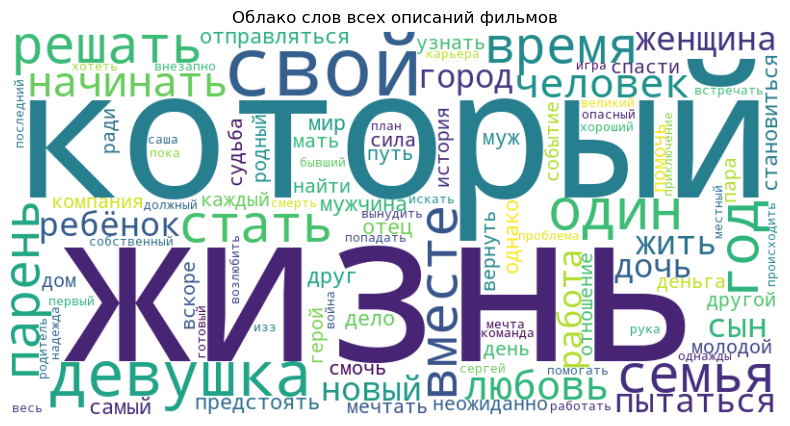

In [15]:
# Определяем доминирующую тему для каждого фильма
dominant_topics = np.argmax(nmf_transformed, axis=1)

# Анализ по годам
df['dominant_topic'] = dominant_topics
yearly_dist = df.groupby('year')['dominant_topic'].value_counts(normalize=True).unstack().fillna(0)

# Показываем последние 20 лет
print(yearly_dist.tail(20).round(3))

# Облако слов для всего корпуса (опционально)
def create_wordcloud(text_series, title):
    text = ' '.join(text_series.dropna().astype(str))
    wordcloud = WordCloud(width=800, height=400, 
                         background_color='white',
                         max_words=100,
                         colormap='viridis').generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(title)
    plt.show()

create_wordcloud(df['text_lemm'], "Облако слов всех описаний фильмов")

# Кластеризация и классификация

In [16]:
import pandas as pd
import numpy as np
import re
import string
import warnings
warnings.filterwarnings('ignore')

# МЕТОД 1: K-MEANS + PCA визуализация

Оптимальное количество кластеров: 9

Метрики качества K-Means:
  Silhouette Score: 0.001
  Calinski-Harabasz Score: 1.4
  Davies-Bouldin Score: 8.100


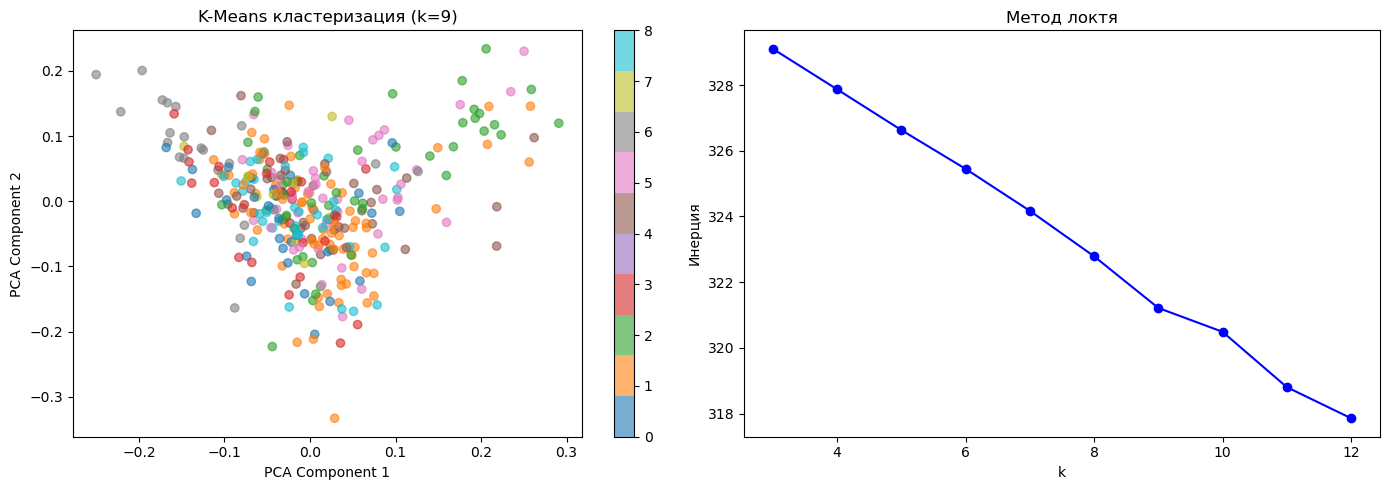


--- Топ-12 слов для каждого кластера K-Means ---

Кластер 1 (29 фильмов):
  Ключевые слова: цена, новый, работа, пытаться, любой цена, любой, сын, жизнь

Кластер 2 (74 фильмов):
  Ключевые слова: семья, который, свой, отец, девушка, жизнь, один, сын

Кластер 3 (50 фильмов):
  Ключевые слова: друг, жизнь, хороший, парень, время, любовь, друг друг, получить

Кластер 4 (28 фильмов):
  Ключевые слова: жизнь, свой, который, привести, навсегда, пик, год, начинать

Кластер 5 (39 фильмов):
  Ключевые слова: саша, сила, мечтать, парень, будущее, жизнь, свой, девушка

Кластер 6 (46 фильмов):
  Ключевые слова: новый, приключение, год, вместе, отправляться, друг, канун, свой

Кластер 7 (24 фильмов):
  Ключевые слова: тренер, история, сборная, игра, победа, спорт, автор, начало

Кластер 8 (12 фильмов):
  Ключевые слова: князь, создание, андрей, сериал, исторический, главный, процесс, фильм

Кластер 9 (38 фильмов):
  Ключевые слова: сергей, другой, разный, ребёнок, иван, врач, свой, самый


In [25]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import matplotlib.pyplot as plt

# Определение оптимального количества кластеров
inertias = []
silhouettes = []
K_range = range(3, 13)

for k in K_range:
    kmeans_test = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_test = kmeans_test.fit_predict(tfidf_matrix)
    inertias.append(kmeans_test.inertia_)
    if len(set(labels_test)) > 1:
        silhouettes.append(silhouette_score(tfidf_matrix, labels_test))
    else:
        silhouettes.append(0)

optimal_k = K_range[np.argmax(silhouettes)]
print(f"Оптимальное количество кластеров: {optimal_k}")

# Финалная кластеризация K-Means
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['cluster_kmeans'] = kmeans.fit_predict(tfidf_matrix)

# Оценка качества
sil_score = silhouette_score(tfidf_matrix, df['cluster_kmeans'])
ch_score = calinski_harabasz_score(tfidf_matrix.toarray(), df['cluster_kmeans'])
db_score = davies_bouldin_score(tfidf_matrix.toarray(), df['cluster_kmeans'])

print(f"\nМетрики качества K-Means:")
print(f"  Silhouette Score: {sil_score:.3f}")
print(f"  Calinski-Harabasz Score: {ch_score:.1f}")
print(f"  Davies-Bouldin Score: {db_score:.3f}")

# Визуализация через PCA
pca = PCA(n_components=2)
tfidf_pca = pca.fit_transform(tfidf_matrix.toarray())

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.scatter(tfidf_pca[:, 0], tfidf_pca[:, 1], c=df['cluster_kmeans'], cmap='tab10', alpha=0.6)
plt.title(f'K-Means кластеризация (k={optimal_k})')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.colorbar()

plt.subplot(1, 2, 2)
plt.plot(K_range, inertias, 'bo-', label='Инерция')
plt.xlabel('k')
plt.ylabel('Инерция')
plt.title('Метод локтя')
plt.tight_layout()
plt.show()

# Топ-12 слов для каждого кластера K-Means (ИСПРАВЛЕНО)
print("\n--- Топ-12 слов для каждого кластера K-Means ---")
for cluster_id in range(optimal_k):
    # Используем numpy array для индексации
    mask = (df['cluster_kmeans'].values == cluster_id)
    cluster_docs = tfidf_matrix[mask]
    if cluster_docs.shape[0] > 0:
        center = cluster_docs.mean(axis=0).A1
        top_words_idx = center.argsort()[-12:][::-1]
        top_words = [feature_names[i] for i in top_words_idx]
        print(f"\nКластер {cluster_id + 1} ({cluster_docs.shape[0]} фильмов):")
        print(f"  Ключевые слова: {', '.join(top_words[:8])}")

# МЕТОД 2: ИЕРАРХИЧЕСКАЯ КЛАСТЕРИЗАЦИЯ

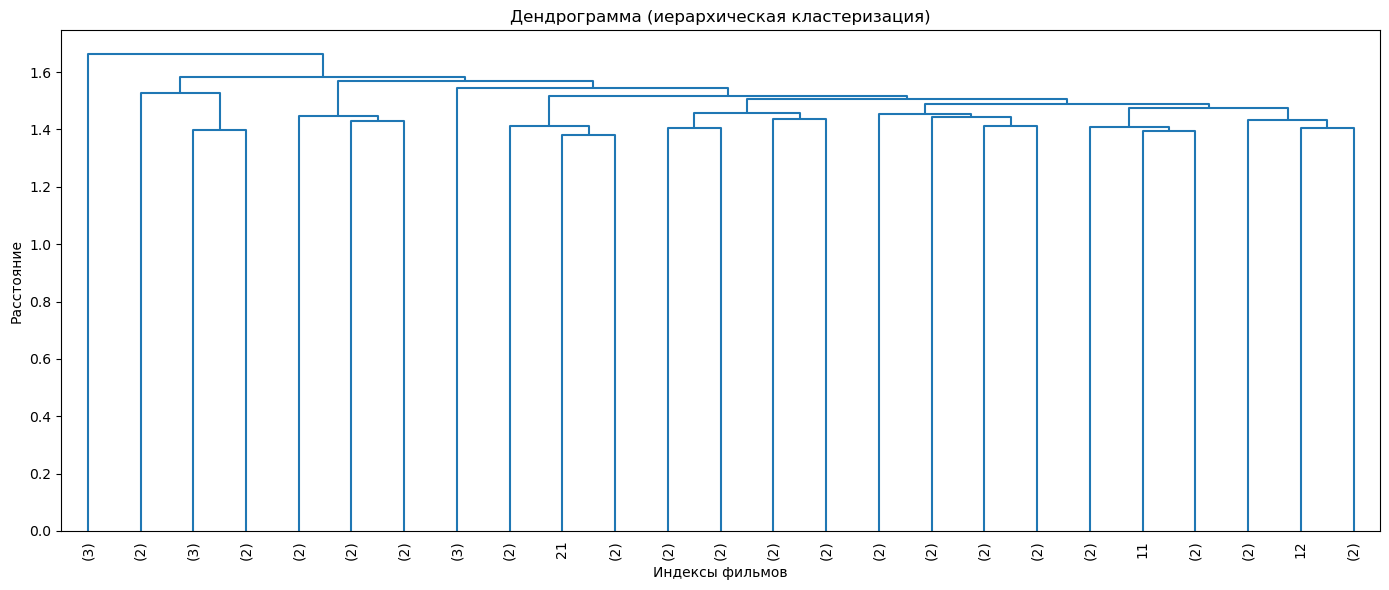


--- Топ-12 слов для каждого кластера (иерархическая) ---

Кластер 1 (173 фильмов):
  Ключевые слова: жизнь, свой, который, год, девушка, один, решать, человек

Кластер 2 (39 фильмов):
  Ключевые слова: стать, ради, никита, жестокий, готовый, создание, роль, картина

Кластер 3 (32 фильмов):
  Ключевые слова: дочь, сын, семья, сергей, муж, жизнь, мария, лариса

Кластер 4 (27 фильмов):
  Ключевые слова: друг, друг друг, новый, хороший, школа, герой, разный, реальность

Кластер 5 (4 фильмов):
  Ключевые слова: ген, милан, заветный мечта, мечта стать, успех, голова, заветный, ради

Кластер 6 (5 фильмов):
  Ключевые слова: новый, канун новый, новый год, канун, год, ольга, подарок, отметить

Кластер 7 (16 фильмов):
  Ключевые слова: сборная, мир, спортсмен, год, олимпийский, тренер, спорт, победа

Кластер 8 (9 фильмов):
  Ключевые слова: саша, друг, душевный, приятно, приятно провести, похожий, родитель, провести время

Кластер 9 (35 фильмов):
  Ключевые слова: дело, иван, планета, город, аг

([<matplotlib.axis.XTick at 0x319e682d0>,
 [Text(1, 0, '1'),
  Text(2, 0, '2'),
  Text(3, 0, '3'),
  Text(4, 0, '4'),
  Text(5, 0, '5'),
  Text(6, 0, '6'),
  Text(7, 0, '7'),
  Text(8, 0, '8'),
  Text(9, 0, '9')])

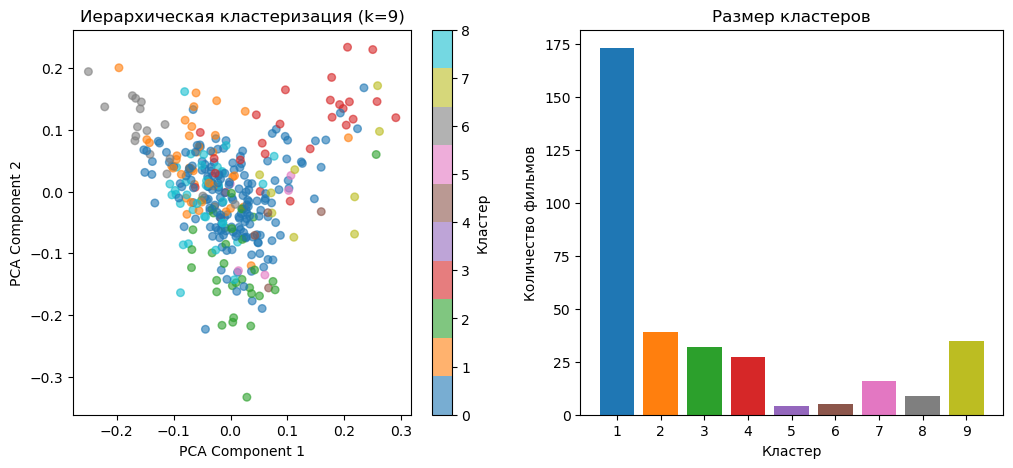

In [26]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

agg_clustering = AgglomerativeClustering(n_clusters=optimal_k, linkage='ward')
df['cluster_hierarchical'] = agg_clustering.fit_predict(tfidf_matrix.toarray())

# Дендрограмма
sample_size = min(50, len(df))
sample_idx = np.random.choice(len(df), sample_size, replace=False)
sample_matrix = tfidf_matrix[sample_idx].toarray()

linkage_matrix = linkage(sample_matrix, method='ward')
plt.figure(figsize=(14, 6))
dendrogram(linkage_matrix, truncate_mode='lastp', p=25, leaf_rotation=90, leaf_font_size=10)
plt.title('Дендрограмма (иерархическая кластеризация)')
plt.xlabel('Индексы фильмов')
plt.ylabel('Расстояние')
plt.tight_layout()
plt.show()

print("\n--- Топ-12 слов для каждого кластера (иерархическая) ---")
for cluster_id in range(optimal_k):
    mask = (df['cluster_hierarchical'].values == cluster_id)
    cluster_docs = tfidf_matrix[mask]
    if cluster_docs.shape[0] > 0:
        center = cluster_docs.mean(axis=0).A1
        top_words_idx = center.argsort()[-12:][::-1]
        top_words = [feature_names[i] for i in top_words_idx]
        print(f"\nКластер {cluster_id + 1} ({cluster_docs.shape[0]} фильмов):")
        print(f"  Ключевые слова: {', '.join(top_words[:8])}")

# Основной график: 2D проекция кластеров (как в K-Means)
plt.figure(figsize=(12, 5))

# График распределения кластеров в PCA пространстве
plt.subplot(1, 2, 1)
scatter = plt.scatter(tfidf_pca[:, 0], tfidf_pca[:, 1], 
                      c=df['cluster_hierarchical'], 
                      cmap='tab10', alpha=0.6, s=30)
plt.title(f'Иерархическая кластеризация (k={optimal_k})', fontsize=12)
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.colorbar(scatter, label='Кластер')

# График размера кластеров
plt.subplot(1, 2, 2)
cluster_sizes = df['cluster_hierarchical'].value_counts().sort_index()
bars = plt.bar(range(1, optimal_k + 1), cluster_sizes.values, 
               color=plt.cm.tab10(range(optimal_k)))
plt.title('Размер кластеров', fontsize=12)
plt.xlabel('Кластер')
plt.ylabel('Количество фильмов')
plt.xticks(range(1, optimal_k + 1))

# МЕТОД 3: NMF (ТЕМАТИЧЕСКОЕ МОДЕЛИРОВАНИЕ)


Silhouette Score NMF: 0.005


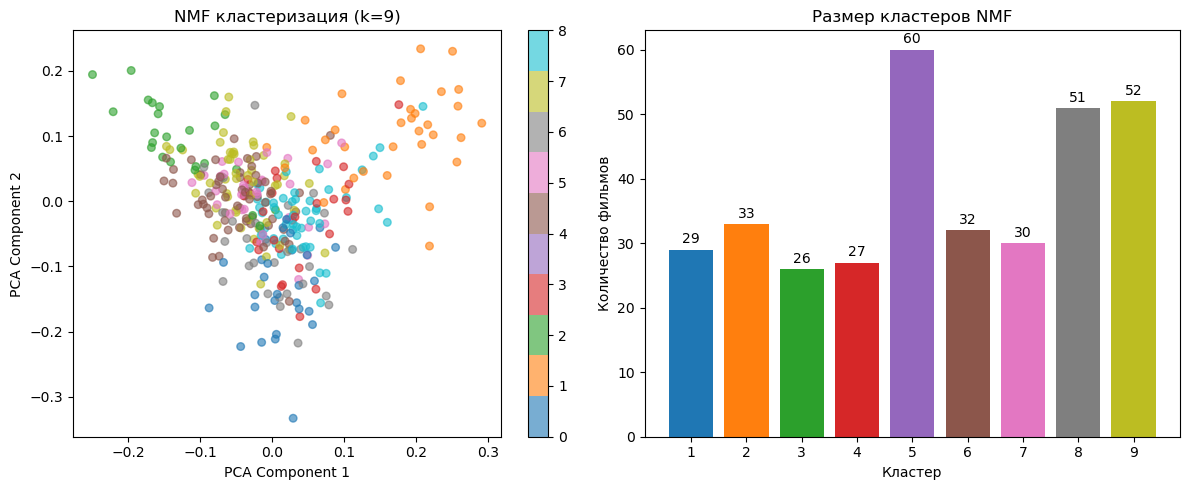


--- Темы NMF ---

Тема 1 (29 фильмов):
  Ключевые слова: дочь, муж, жизнь, ребёнок, жена, женщина, сергей, семья

Тема 2 (33 фильмов):
  Ключевые слова: друг, друг друг, хороший, саша, хороший друг, каждый, помочь, собака

Тема 3 (26 фильмов):
  Ключевые слова: тренер, сборная, команда, победа, игра, спортсмен, год, спорт

Тема 4 (27 фильмов):
  Ключевые слова: новый, год, новый год, канун новый, канун, приключение, праздник, чудо

Тема 5 (60 фильмов):
  Ключевые слова: советский, война, один, предстоять, агент, задание, становиться, должный

Тема 6 (32 фильмов):
  Ключевые слова: дело, сам, сам дело, желание, детство, понять, хотеться, сон

Тема 7 (30 фильмов):
  Ключевые слова: сын, виктор, начинать, цена, маша, отец, ребёнок, работа

Тема 8 (51 фильмов):
  Ключевые слова: мечтать, роль, стать, готовый, ради, который, актёр, мечтать стать

Тема 9 (52 фильмов):
  Ключевые слова: свой, мечта, день, девушка, вместе, ген, семья, дом


In [27]:
from sklearn.decomposition import NMF
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

nmf = NMF(n_components=optimal_k, random_state=42, init='nndsvd')
nmf_features = nmf.fit_transform(tfidf_matrix)
df['cluster_nmf'] = np.argmax(nmf_features, axis=1)

# График силуэта для NMF
sil_score_nmf = silhouette_score(tfidf_matrix, df['cluster_nmf'])
print(f"\nSilhouette Score NMF: {sil_score_nmf:.3f}")

# Визуализация кластеров NMF (как в K-Means)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
scatter = plt.scatter(tfidf_pca[:, 0], tfidf_pca[:, 1], 
                      c=df['cluster_nmf'], cmap='tab10', alpha=0.6, s=30)
plt.title(f'NMF кластеризация (k={optimal_k})')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.colorbar(scatter)

plt.subplot(1, 2, 2)
cluster_sizes = df['cluster_nmf'].value_counts().sort_index()
bars = plt.bar(range(1, optimal_k + 1), cluster_sizes.values, color=plt.cm.tab10(range(optimal_k)))
plt.title('Размер кластеров NMF')
plt.xlabel('Кластер')
plt.ylabel('Количество фильмов')
plt.xticks(range(1, optimal_k + 1))

for bar, size in zip(bars, cluster_sizes.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
             str(size), ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

print("\n--- Темы NMF ---")
for topic_idx in range(optimal_k):
    topic_words_idx = nmf.components_[topic_idx].argsort()[-12:][::-1]
    topic_words = [feature_names[i] for i in topic_words_idx]
    n_films = (df['cluster_nmf'] == topic_idx).sum()
    print(f"\nТема {topic_idx + 1} ({n_films} фильмов):")
    print(f"  Ключевые слова: {', '.join(topic_words[:8])}")